![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluate — the Report

*Project 3 — AI Product: From Model to Product*

**Team:** Theophilus Kobina Sarpey
**Track:** both — model track (voltage models, failure screening, comment NLP) and LLM track (RAG, agent, report)
**Data:** ECSIM PEM fuel-cell dataset (Hamidi, Haghighi, Askari 2020, doi:10.26434/chemrxiv.11902023, CC BY 4.0) + 30 curated knowledge notes (`data/knowledge/`)

---

**This notebook holds the report.** It is read on its own, by someone who has not seen notebooks 01 and 02: the question, the evidence, what was concluded and how far to trust it.

> **Done when:** the final versions are evaluated once, their failures are analysed with examples, their cost is known, and the conclusions answer the question framed in notebook 01.

---
## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path
# Run from the project root or from notebooks/: find the folder that contains src/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIG_DIR, MODELS_DIR, REPORTS_DIR, SEED, ensure_dirs
ensure_dirs()
from src.functions import *          # template convention: reusable logic lives in src/
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def savefig(name):
    """Save the current figure into reports/figures/ for the README and slides."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=130)

## Live or offline? (set this once)

The next cell is the **connection panel**. Set `USE_LIVE`, and either keep your key in `.env` (`OPEN_AI_KEY`, `OPEN_AI_MODEL=GPT-6-LUNA`) or set `ASK_FOR_KEY = True` for a hidden prompt. It sends one tiny test call and prints `MODE: LIVE` or `MODE: OFFLINE`. If the model name is rejected, the notebook simply continues offline. Everything below works in both modes; cells that differ show the **offline and live answers side by side**.

In [2]:
# ============================================================
# PEMFC-CATHODE-AI: LIVE LLM CONNECTION
# ============================================================

import os
from pathlib import Path

from dotenv import load_dotenv
from openai import OpenAI

# ------------------------------------------------------------
# 1. USER SETTINGS
# ------------------------------------------------------------

USE_LIVE = True
ASK_FOR_KEY = True 

MODEL_NAME = None
# None = use OPENAI_MODEL from .env

# ------------------------------------------------------------
# 2. LOAD ENVIRONMENT
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():

    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Project .env file could not be located."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(
    PROJECT_ROOT / ".env",
    override=True
)

# ------------------------------------------------------------
# 3. READ API CONFIGURATION
# ------------------------------------------------------------

API_KEY = (
    os.getenv("OPENAI_API_KEY")
    or os.getenv("OPENAI_KEY")
)

MODEL = (
    MODEL_NAME
    or os.getenv("OPENAI_MODEL")
    or "gpt-6-luna"
).strip().lower()

# Optional secure interactive key input
if ASK_FOR_KEY and not API_KEY:

    from getpass import getpass

    API_KEY = getpass("Enter OpenAI API key: ")

# ------------------------------------------------------------
# 4. INITIALIZE CLIENT
# ------------------------------------------------------------

client = None
llm = None

MODE = "OFFLINE"
ok = False
msg = "Offline mode selected."

if USE_LIVE:

    if not API_KEY:

        msg = "API key missing."

    else:

        try:

            client = OpenAI(
                api_key=API_KEY,
                timeout=30.0,
                max_retries=2
            )

            # ------------------------------------------------
            # 5. REAL API HEALTH CHECK
            # ------------------------------------------------

            response = client.responses.create(
                model=MODEL,
                input="Reply with exactly: OK",
                max_output_tokens=32
            )

            if response.output_text.strip():

                MODE = "LIVE"
                ok = True

                msg = "OpenAI API connection successful."

        except Exception as e:

            MODE = "OFFLINE"
            ok = False

            msg = (
                f"{type(e).__name__}: {str(e)}"
            )

# ------------------------------------------------------------
# 6. FINAL STATUS
# ------------------------------------------------------------

print("=" * 60)
print("PEMFC-CATHODE-AI LLM CONNECTION")
print("=" * 60)

print("Project:", PROJECT_ROOT)
print("Mode:", MODE)
print("Model:", MODEL)
print("API key detected:", bool(API_KEY))
print("Connection:", "SUCCESS" if ok else "FAILED")
print("Message:", msg)

print("=" * 60)

PEMFC-CATHODE-AI LLM CONNECTION
Project: /Users/theophiluskobinasarpey/Documents/DSML_SEP2026 | IRONHACK/Week 9/Day 1/pemfc-cathode-ai 5
Mode: LIVE
Model: gpt-6-luna
API key detected: True
Connection: SUCCESS
Message: OpenAI API connection successful.


---
## 1. The question

**User:** an electrochemist with a fresh PEM fuel-cell polarisation curve. **Question:** *where does this cell lose voltage, which parameters should I check, and what should I change next?* **Decision supported:** which confirming measurement or change to make next and which curves to distrust.

| Component | Metric | Baseline | Final version |
|---|---|---|---|
| Voltage model (model track) | MAE (V) on held-out **files** | mean predictor ≈ 0.19 V | Random Forest, evaluated once below |
| DFT screening (model track, core) | Spearman, top-10% recall, MAE of U_L, interval coverage, leave-one-system-out | single-quantity rankings; DFT-volcano oracle | Gaussian process / forest on cheap features, below |
| Failure-zone screening | zone accuracy and detection on **injected faults** | no faults labelled in the data | physics + peer screening, below |
| Knowledge answers (LLM track) | hit@4, refusals, valid citations, cost | BM25 keyword search; LLM alone (live) | hybrid RAG + grounded prompt |
| Comment NLP | macro-F1 on unseen wording (synthetic) | majority class, lexicon rule | TF-IDF + lexicon LR (notebook 02) |

**Data and scope.** ECSIM dataset (Pt/C cathodes, H2/O2, one laboratory, CC BY 4.0) + 30 original knowledge notes. Nothing here says anything about other catalysts or air operation.

---
## 2. The final evaluation

### 2a. Voltage model — the held-out files, scored once

In [3]:
import json, joblib
from src.data import load_polarization
from src.models import FEATURES, TARGET, GROUP, holdout_split, model_zoo, final_test
pol = load_polarization()
train, test = holdout_split(pol)
best_name = pd.read_csv(REPORTS_DIR / "model_comparison.csv").model.iloc[0]
zoo = model_zoo()
m_best, pred_df = final_test(zoo[best_name], train, test)        # the ONE look at the test files
m_base, _ = final_test(zoo["Mean baseline"], train, test)
cv = pd.read_csv(REPORTS_DIR / "model_comparison.csv").set_index("model").loc[best_name]
fitted = joblib.load(MODELS_DIR / "voltage_model.joblib")      # trained on the training files only (notebook 02)
res = pd.DataFrame([{"model": best_name, **m_best}, {"model": "Mean baseline", **m_base}]).round(4)
res.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)
print(f"validation (grouped CV) MAE {cv.MAE_V_mean:.4f} +/- {cv.MAE_V_std:.4f} V  ->  test MAE {m_best['MAE_V']:.4f} V")
res

validation (grouped CV) MAE 0.0904 +/- 0.0178 V  ->  test MAE 0.0797 V


,model,MAE_V,RMSE_V,R2
0,Random Forest,0.0797,0.1083,0.7660
1,Mean baseline,0.1937,0.2243,-0.0032


,n,MAE_V
source_file,,
Activation Test MEA Cycling Potential/5.csv,93.0,0.112
Activation Test MEA Constant Current 0.25A/4.csv,141.0,0.094
Standard Test of Nafion Membrane 112/1.csv,623.0,0.086
Activation Test MEA Constant Voltage 0.6V-4/4.csv,143.0,0.079
Activation Test MEA Constant Voltage 0.6V-4/6.csv,142.0,0.056
Activation Test MEA Constant Voltage 0.6V-3/6.csv,143.0,0.041


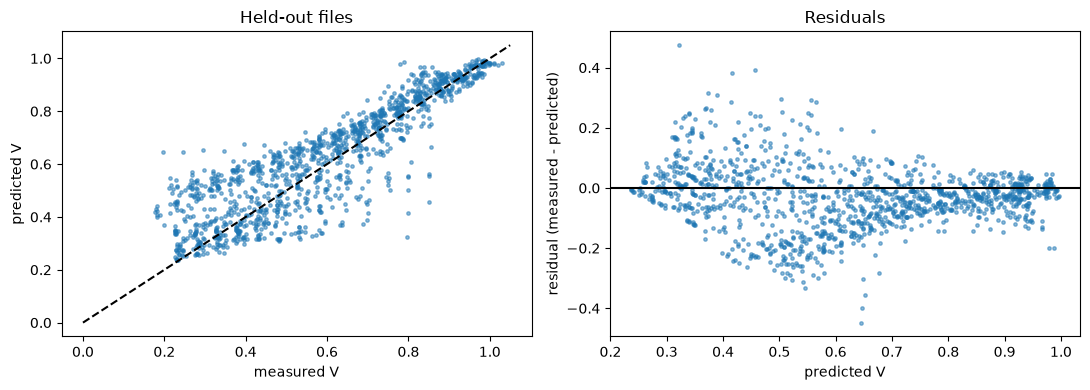

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pred_df.cell_voltage, pred_df.predicted_voltage, s=6, alpha=0.5)
ax[0].plot([0, 1.05], [0, 1.05], "k--"); ax[0].set(xlabel="measured V", ylabel="predicted V", title="Held-out files")
ax[1].scatter(pred_df.predicted_voltage, pred_df.residual, s=6, alpha=0.5); ax[1].axhline(0, color="k")
ax[1].set(xlabel="predicted V", ylabel="residual (measured - predicted)", title="Residuals")
savefig("03_test_predictions.png")

seg = pred_df.groupby("source_file").apply(lambda g: pd.Series({"n": len(g), "MAE_V": g.residual.abs().mean()})).sort_values("MAE_V", ascending=False)
seg.round(3)

### 2b-bis. DFT screening: ranking, uncertainty and the out-of-distribution flag

Leave-one-chemical-system-out (a new alloying element each time). Baselines are scored on the same table.

In [5]:
from src.functions import get_context, get_dft
from src.dft_ml import loso_evaluate, evaluate_baselines, Screener
ctx = get_context(llm=llm)
info = get_dft(ctx); dft = info["table"]; DEMO = not info["trusted"]
if DEMO:
    print("!" * 78 + "\n  SYNTHETIC DEMO DATA: the numbers below test the METHOD, not real catalysts. Do not quote them.\n" + "!" * 78)
print("source:", info["source"], "| rows", len(dft), "| systems", dft.chemical_system.nunique())
ml_direct, oof = loso_evaluate(dft)
ml_volc, _ = loso_evaluate(dft, route="dG_OH -> volcano")
base = evaluate_baselines(dft)
final_dft = pd.concat([base.assign(model=base.method, route="baseline (no ML)").drop(columns="method"), ml_direct, ml_volc], ignore_index=True)
final_dft.to_csv(REPORTS_DIR / "dft_final_evaluation.csv", index=False)
final_dft[["model", "route", "needs_DFT_for_candidate", "MAE_U_L_V", "spearman", "top10pct_recall", "coverage_90pct"]].round(3)

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  SYNTHETIC DEMO DATA: the numbers below test the METHOD, not real catalysts. Do not quote them.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
source: SYNTHETIC DEMO TABLE (not DFT) | rows 111 | systems 10


,model,route,needs_DFT_for_candidate,MAE_U_L_V,spearman,top10pct_recall,coverage_90pct
0,strain heuristic (compressive = better),baseline (no ML),False,NaN,-0.663,0.000,NaN
1,electronegativity vs Pt (closer = better),baseline (no ML),False,NaN,0.595,0.091,NaN
2,d-band centre (lower = better),baseline (no ML),True,NaN,0.256,0.364,NaN
3,ORACLE: volcano from the DFT dG_OH (needs DFT),baseline (no ML),True,NaN,0.842,0.182,NaN
4,Gaussian Process,U_L direct,NaN,0.071,0.741,0.000,0.928
5,Random Forest,U_L direct,NaN,0.074,0.705,0.182,0.811
6,Gradient Boosting,U_L direct,NaN,0.074,0.702,0.273,NaN
7,Ridge,U_L direct,NaN,0.088,0.739,0.091,NaN
8,Gaussian Process,dG_OH -> volcano,NaN,0.091,0.827,0.364,0.685
9,Ridge,dG_OH -> volcano,NaN,0.091,0.767,0.182,NaN


In [6]:
# Does the out-of-distribution flag fire when a whole chemical system is new? Fit on the other systems, score the held-out one.
rows = []
for sysname, g in dft.groupby("chemical_system"):
    tr = dft[dft.chemical_system != sysname]
    sc = Screener(tr)
    out = sc.score(g[["composition", "facet", "structure"]].drop_duplicates())
    rows.append({"held_out_system": sysname, "candidates": len(out), "flagged_new_system_rule": float(out.new_system.mean()),
                 "flagged_by_distance_only": float((out.ood_ratio > 2.0).mean()), "mean_pred_sd_V": float(out.pred_sd.mean())})
ood = pd.DataFrame(rows); print(ood.round(3).to_string(index=False))
print("\nShare flagged by the new-system rule:", round(ood.flagged_new_system_rule.mean(), 2), "| by feature distance alone:", round(ood.flagged_by_distance_only.mean(), 2))

held_out_system  candidates  flagged_new_system_rule  flagged_by_distance_only  mean_pred_sd_V
          Ag-Pt          12                      1.0                       0.0           0.122
          Au-Pt          12                      1.0                       0.0           0.112
          Co-Pt          12                      1.0                       0.0           0.080
          Cu-Pt          12                      1.0                       0.0           0.113
          Fe-Pt          12                      1.0                       0.0           0.120
          Ir-Pt          12                      1.0                       0.0           0.123
          Ni-Pt          12                      1.0                       0.0           0.091
          Pd-Pt          12                      1.0                       0.0           0.100
             Pt           3                      1.0                       0.0           0.121
          Pt-Rh          12                      1

In [7]:
# Calibration of the Gaussian-process interval, and the worst errors
gp = ml_direct[ml_direct.model == "Gaussian Process"].iloc[0]
print(f"GP 90% interval coverage under leave-one-system-out: {gp.coverage_90pct:.2f} (nominal 0.90), mean sd {gp.mean_sd_V:.3f} V")
oof["abs_err"] = (oof["pred_Gaussian Process"] - oof["U_L"]).abs()
oof.sort_values("abs_err", ascending=False).head(6)[["composition", "facet", "U_L", "pred_Gaussian Process", "sd_Gaussian Process", "abs_err"]].round(3)

GP 90% interval coverage under leave-one-system-out: 0.93 (nominal 0.90), mean sd 0.107 V


,composition,facet,U_L,pred_Gaussian Process,sd_Gaussian Process,abs_err
94,PtAu,111,0.412,0.787,0.124,0.374
16,Pt3Co,111,0.750,0.483,0.078,0.268
38,PtFe,110,0.113,0.379,0.123,0.266
93,PtAu,111,0.505,0.752,0.124,0.247
1,Pt3Ni,111,0.436,0.662,0.088,0.226
88,Pt3Au,111,0.593,0.800,0.100,0.207


**Reading it.** (1) Compare each ML row with the baselines *and* with the oracle (the DFT ΔG_OH volcano, which needs the calculation ML tries to avoid): ML is only worth using if it ranks clearly better than the cheap single-quantity baselines at a fraction of the DFT cost. (2) Check the coverage: far below 90% means the model is over-confident. (3) The new-system rule flags every held-out candidate **by construction** (the element is absent from the training table), so that column is a sanity check, not evidence. The honest test is the *distance-only* column: where it is low, the feature-space distance does not notice the new chemistry and the model can be confidently wrong about it; the rule that compares the element list is what protects the user. (4) The worst errors are the candidates to look at by hand before trusting any ranking.

### 2b. Failure-zone screening — injected faults

No curve carries a fault label, so known faults are added to healthy curves and the **whole corpus is re-screened**, as a new measurement would be.

In [8]:
from src.functions import get_context
from src.evaluation import fault_injection_eval
ctx = get_context()
fi = fault_injection_eval(ctx, n_per_cell=25)
summary = fi.groupby(["fault", "severity"]).agg(n=("correct", "size"), detected=("detected", "mean"), zone_correct=("correct", "mean")).round(2)
summary

n  detected  zone_correct
fault          severity                            
kinetic        0.04      25      0.44          0.36
               0.08      25      0.64          0.60
               0.15      25      0.20          0.20
mass_transport 0.05      25      0.28          0.28
               0.12      25      0.64          0.64
               0.25      25      0.96          0.96
ohmic          0.10      25      0.32          0.28
               0.20      25      0.40          0.36
               0.40      25      0.24          0.24

predicted       kinetic  mass_transport  none  ohmic  unreliable_fit
fault                                                               
kinetic              29               1    23      2              20
mass_transport        0              47    28      0               0
ohmic                 0               2    34     22              17

Of 103 detected faults, 95% were assigned the right zone; overall 46% of injected faults were detected.


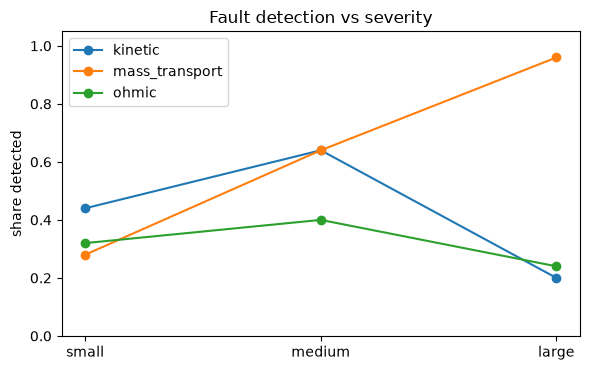

In [9]:
print(pd.crosstab(fi.fault, fi.predicted))
det = fi[fi.detected]
print(f"\nOf {len(det)} detected faults, {det.correct.mean():.0%} were assigned the right zone; overall {fi.detected.mean():.0%} of injected faults were detected.")
fi.to_csv(REPORTS_DIR / "fault_injection.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.8))
for kind, g in fi.groupby("fault"):
    s = g.groupby("severity").detected.mean()
    ax.plot(range(len(s)), s.values, "o-", label=kind)
ax.set(xticks=range(3), xticklabels=["small", "medium", "large"], ylabel="share detected", ylim=(0, 1.05), title="Fault detection vs severity")
ax.legend()
savefig("02_fault_detection.png")

**Reading the result.** When a fault is detected, the zone named is almost always the right one (see the printed share and the few off-diagonal cells above), which is what matters for a *diagnosis*. Detection is incomplete for small faults, and very large kinetic or ohmic faults often end up as `unreliable_fit`, because a big shift moves the 0.45–0.80 V fit window and distorts the linear fit. So: **a flag is trustworthy; the absence of a flag is not proof of health**, and `unreliable_fit` means "look at this curve yourself".

### 2c. Knowledge answers — the whole evaluation set

In [10]:
from src.functions import get_context
from src.evaluation import load_questions, retrieval_eval, qa_eval, qa_summary
ctx = get_context(llm=llm)
questions = load_questions()
q = pd.DataFrame(questions)
print(f"{len(q)} questions; {int((~q.answerable).sum())} out of scope | mode: {MODE}")

38 questions; 6 out of scope | mode: LIVE


## 3. Answers: citations, abstention, cost

`qa_eval` runs the whole path (retrieve → relevance gate → LLM or extractive fallback → citation check) on every question. For each answerable question we check that the system **answers and cites a gold note**; for each out-of-scope question we check that it **refuses**.

In [11]:
res = qa_eval(ctx, questions, k=4)
res.drop(columns="answer").round(4)

,id,answerable,category,mode,abstained,behaved,retrieved_gold,cited_gold,has_citation,invalid_citations,unsupported_links,prompt_tokens,completion_tokens,cost_usd,seconds
0,Q01,True,kinetics,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0016
1,Q02,True,kinetics,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0019
2,Q03,True,catalyst,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0017
3,Q04,True,catalyst,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0010
4,Q05,True,durability,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0009
5,Q06,True,durability,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0008
6,Q07,True,catalyst-layer,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0008
7,Q08,True,water,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0008
8,Q09,True,operating,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0008
9,Q10,True,ohmic,offline-extractive,False,True,True,True,True,0,0,0,0,0.0,0.0009


In [12]:
summ = qa_summary(res)
pd.Series(summ).to_frame("value")

,value
answerable_answered,1.00000
out_of_scope_refused,0.50000
cited_gold_when_answered,0.84375
invalid_citations_total,0.00000
unsupported_links_total,0.00000
mean_seconds,0.00092
mean_prompt_tokens,0.00000
mean_completion_tokens,0.00000
mean_cost_usd,0.00000


In [13]:
res.to_csv(REPORTS_DIR / "qa_eval.csv", index=False)
print("Modes used:", res["mode"].value_counts().to_dict())

Modes used: {'offline-extractive': 35, 'abstained': 3}


### 2d. Comment NLP

Scored in notebook 02 on unseen observation wording (synthetic corpus):

In [14]:
pd.read_csv(REPORTS_DIR / "review_model_scores.csv", index_col=0).round(3)

,mean,std
sent: majority,0.149,0.019
sent: lexicon rule,0.839,0.089
sent: TF-IDF+lexicon LR,0.922,0.035
aspect: TF-IDF LR,0.497,0.078
aspect: chance (1/6),0.167,0.000


---
## 3. Where it goes wrong

### 3a. Voltage model: by file, and what it relies on

In [15]:
seg = pred_df.groupby("source_file").apply(lambda g: pd.Series({"n": len(g), "MAE_V": g.residual.abs().mean()})).sort_values("MAE_V", ascending=False)
seg.round(3)

,n,MAE_V
source_file,,
Activation Test MEA Cycling Potential/5.csv,93.0,0.112
Activation Test MEA Constant Current 0.25A/4.csv,141.0,0.094
Standard Test of Nafion Membrane 112/1.csv,623.0,0.086
Activation Test MEA Constant Voltage 0.6V-4/4.csv,143.0,0.079
Activation Test MEA Constant Voltage 0.6V-4/6.csv,142.0,0.056
Activation Test MEA Constant Voltage 0.6V-3/6.csv,143.0,0.041


In [16]:
from sklearn.inspection import permutation_importance
r = permutation_importance(fitted, test[FEATURES], test[TARGET], n_repeats=15, random_state=SEED,
                           scoring="neg_mean_absolute_error")
imp = pd.DataFrame({"feature": FEATURES, "MAE_increase_V": r.importances_mean, "std": r.importances_std}).sort_values("MAE_increase_V", ascending=False)
imp.round(4)

,feature,MAE_increase_V,std
0,current_density,0.1726,0.0032
3,membrane_compression,0.0053,0.0003
1,pressure,0.0052,0.0006
6,test_family,0.0034,0.0006
5,operating_set,0.0029,0.0003
2,relative_humidity,0.0009,0.0008
4,nafion_percent,-0.0000,0.0000


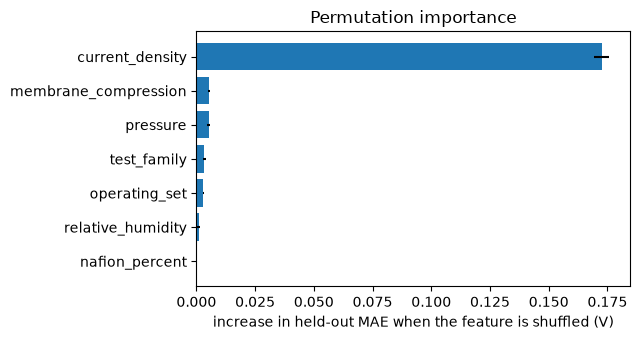

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.barh(imp.feature[::-1], imp.MAE_increase_V[::-1], xerr=imp["std"][::-1])
ax.set(xlabel="increase in held-out MAE when the feature is shuffled (V)", title="Permutation importance")
savefig("03_permutation_importance.png")

Current density dominates, as it must (it sets the position on the curve). The condition variables matter much less *for predicting voltage*; that does not mean they are unimportant for performance. Permutation importance measures predictive reliance on shuffling one column, and it can understate variables that are correlated or missing for most rows (compression and Nafion % exist only in one file). The physics-level question *what moves peak power?* is answered next from the curves themselves.

**Reading.** The error is largest for the held-out files whose protocol differs most from the training files. A held-out *file* is a new experiment: the model has never seen that test's activation history. **Do not use it for another cell, catalyst or laboratory.** Current density dominates the prediction; the condition effects on *performance* are read from the curves (notebook 02), not from permutation importance (which understates variables that are correlated or recorded for only one file).

### 3b. Failure screening

* **Flags are credible, silence is not proof.** When a fault is detected the zone is almost always right (above), but detection of small faults is incomplete, and very large kinetic or ohmic faults often end up as `unreliable_fit` because a big shift moves the 0.45-0.80 V fit window.
* **Peer-relative thresholds (z ≥ 1.5)** are screening heuristics, not validated failure criteria.
* **A polarisation curve narrows the cause but does not prove it:** every diagnosis ends with the confirming measurement (EIS, crossover test, CV/ECSA, repeat run).

### 3c. Knowledge answers — every failure, read in full

In [18]:
bad = res[~res.behaved | (res.answerable & (res.cited_gold == False))]
for r in bad.itertuples():
    print(f"{r.id} [{r.category}] answerable={r.answerable} abstained={r.abstained} mode={r.mode}")
    print("   Q:", q.set_index('id').loc[r.id, 'question']); print("   A:", r.answer[:300].replace('\n', ' '))
print(len(bad), "problem rows")

Q14 [protocol] answerable=True abstained=False mode=offline-extractive
   Q: Why do new MEAs need an activation procedure?
   A: The activation procedure uses constant voltage, cycling potential or constant current, in repeated sets. [S1] A polarisation curve narrows the list; confirmation needs a second measurement such as EIS, CV, crossover LSV or a recovery procedure. [S2] The ECSIM PEM Fuel Cell Dataset (Hamidi, Haghighi,
Q24 [out-of-scope] answerable=False abstained=False mode=offline-extractive
   Q: What activation energy for ORR did the ECSIM authors report for their Pt/C electrodes?
   A: Present data cannot rank Fe-N-C against Pt/C because ECSIM contains only Pt/C electrodes. [S2] In the ECSIM dataset both electrodes are 20 wt% Pt/C with a loading of about 0.38-0.39 mg Pt per cm2. [S3] Electrodes are Pt/C 20 wt% on carbon paper with about 0.38-0.39 mg Pt per cm2. [S1]
Q27 [dft] answerable=True abstained=False mode=offline-extractive
   Q: How is the ORR limiting potential obt

**What fails and why.**

* **The ECSIM "activation energy" question (Q24)** *looks* covered: the words ECSIM, ORR and Pt/C all occur in the notes, so the relevance gate lets it through, and the offline extractive fallback happily returns the closest sentences. This is the classic RAG failure: *topical overlap is not an answer*. With an LLM and the `NOT_IN_KB` rule the question should be refused, but that must be **verified with your key**, not assumed; rerun this notebook with `OPEN_AI_KEY` set and compare the `mode` column.
* Answers that cite a non-gold note: the extractive fallback picks the highest-overlap sentence, which may come from a neighbouring note. The cited note is still a real retrieved source, so nothing is invented, but it may not be the best one.
* No invalid citations and no unsupported links appear, because every sentence is copied from a retrieved note (offline) or checked after generation (online).

**Where not to trust the product:** questions about other catalysts' measured numbers, air operation, durability over time, or anything outside the 30 notes; any claim about *why* a specific curve fails (the curve narrows, it does not prove).

### 3d. Comments

The aspect classifier (macro-F1 ≈ 0.5, chance 0.17) fails on wording it has never seen and on comments that mix aspects; sentiment is much better (≈ 0.9) partly because the lexicon was written by the same author as the phrases. Treat the tags as suggestions and collect **real labelled comments** before trusting them.

### Where the product should **not** be trusted
1. Other catalysts (alloys, Fe-N-C), air operation, durability over time: not in the data, only in labelled literature notes.
2. Any claim about *why* a specific curve fails: a zone and a next measurement, not a proof.
3. Questions that look covered by the notes but are not (the ECSIM activation-energy question): offline mode cannot tell; only the live model plus `NOT_IN_KB` can, and that must be verified with your key.
4. Voltage predictions for a new cell, laboratory or protocol.

---
## 4. Cost and speed

In [19]:
meta = json.loads((MODELS_DIR / "voltage_model_meta.json").read_text())
fitted = joblib.load(MODELS_DIR / "voltage_model.joblib")
import time
t0 = time.perf_counter(); fitted.predict(test[FEATURES].head(1)); one_ms = (time.perf_counter() - t0) * 1000
print(f"Voltage model ({meta['model']}): training {meta['fit_seconds']:.1f} s, size {meta['size_mb']:.0f} MB on disk, {one_ms:.0f} ms to predict one point")

Voltage model (Random Forest): training 0.3 s, size 41 MB on disk, 29 ms to predict one point


In [20]:
cost = res.groupby("mode").agg(questions=("id", "size"), mean_seconds=("seconds", "mean"),
                              mean_prompt_tokens=("prompt_tokens", "mean"), mean_completion_tokens=("completion_tokens", "mean"),
                              mean_cost_usd=("cost_usd", "mean")).round(4)
print("LLM client usage so far:", llm.total.as_dict() if hasattr(llm, 'total') else {})
cost

LLM client usage so far: {}


,questions,mean_seconds,mean_prompt_tokens,mean_completion_tokens,mean_cost_usd
mode,,,,,
abstained,3,0.0006,0.0,0.0,0.0
offline-extractive,35,0.0009,0.0,0.0,0.0


In [21]:
# What would 1,000 questions a day cost per month? Needs a live run and prices (OPEN_AI_PRICE_IN_PER_1M / _OUT_PER_1M).
from src.config import get_llm_settings
st = get_llm_settings()
d = pd.read_csv(REPORTS_DIR / "qa_eval.csv")
tok_in, tok_out = d.prompt_tokens.mean(), d.completion_tokens.mean()
if st.price_in_per_1m is not None and tok_in > 0:
    monthly = 1000 * 30 * (tok_in * st.price_in_per_1m + tok_out * st.price_out_per_1m) / 1e6
    print(f"~${monthly:,.0f} per month for 1,000 questions/day at {tok_in:.0f}+{tok_out:.0f} tokens per question")
else:
    print("Not computed: the stored run was offline (0 tokens) or prices are not set. Run this notebook with a live key and "
          "OPEN_AI_PRICE_IN_PER_1M / OPEN_AI_PRICE_OUT_PER_1M set to fill this in.")

Not computed: the stored run was offline (0 tokens) or prices are not set. Run this notebook with a live key and OPEN_AI_PRICE_IN_PER_1M / OPEN_AI_PRICE_OUT_PER_1M set to fill this in.


Reference design (not measured here, so no number is claimed): a grounded answer sends about four 100-word notes plus the question, i.e. a few hundred to roughly a thousand prompt tokens, and returns a few hundred tokens. The relevance gate removes obviously out-of-scope questions *before* any call, and the agent caps steps at 6. Fill the table above by running this notebook with a key and prices set.

---
## 5. The saved pipeline, used as the app uses it

Reload what was saved in notebook 02 and run it on a **new** example: a curve the app user uploads.

In [22]:
from src.functions import diagnose_uploaded_curve, diagnose_curve, suggest_changes
new = pd.DataFrame({"current_density": [60, 150, 300, 500, 700, 900, 1100, 1300, 1500, 1700],
                    "cell_voltage":    [0.88, 0.80, 0.74, 0.68, 0.62, 0.55, 0.47, 0.38, 0.28, 0.20]})   # an example upload
d = diagnose_uploaded_curve(ctx, new)
print(d["zone_label"], "|", d["likely_component"]); print("badness z vs corpus:", d["badness_z_vs_corpus"]); print("flags:", d["flags"])
print("\nvoltage model reloaded: predicted V at 500 mA/cm2, 15 psig, 50 % RH, set 1:",
      round(float(fitted.predict(pd.DataFrame([{"current_density": 500, "pressure": 15, "relative_humidity": 50, "membrane_compression": np.nan,
            "nafion_percent": np.nan, "operating_set": 1, "test_family": "Activation Test MEA Standard Protocol"}]))[0]), 3), "V")
print(d["caveat"])

No zone stands out | -
badness z vs corpus: {'kinetic': -0.77, 'ohmic': 0.46, 'mass_transport': 0.39, 'power': 0.39}
flags: []

voltage model reloaded: predicted V at 500 mA/cm2, 15 psig, 50 % RH, set 1: 0.688 V
compared with the whole corpus (conditions unknown); a curve at low pressure or humidity will look weak for that reason alone


---
## 6. The R&D intelligence agent

Bibliographic facts (DOI, title, authors, year) come only from Crossref or a CSV you supply; the LLM only restates abstracts. The digest is checked: any DOI not in the fetched records is reported.

In [23]:
from src.rd_monitor import Paper, fetch_crossref, triage, build_digest, verify_digest, dedupe
papers = []
try:
    papers = dedupe(fetch_crossref("oxygen reduction catalyst PEM fuel cell cathode", days=60, rows=8))
    print(f"fetched {len(papers)} records from Crossref")
except Exception as exc:
    print("Crossref not reachable here (", type(exc).__name__, "): using a clearly fake unit-test record instead")
if not papers:
    # UNIT-TEST FIXTURE: invented on purpose, the 10.0000 prefix is not a registered DOI prefix
    papers = [Paper("10.0000/fixture-not-a-real-paper", "Oxygen reduction on Pt/C cathodes in PEMFC: a fixture record",
                    "Fixture Author", 2026, "Fixture Journal", "")]
tri, usage = triage(papers, llm)
digest = build_digest(tri, min_relevance=0)
print(digest[:1800])

fetched 8 records from Crossref
# R&D intelligence digest

**Cell continuous extraction-HPLC determination biological affinity of 8 bufadienolides on MGC-803 cells and their correlation with anti-tumor activities** (2100, China Journal of Chinese Materia Medica)  
DOI: 10.4268/cjcmm20110225 · relevance 0/3 · topic: unclassified · scored by keyword  
No abstract available.

**Data Science as a Catalyst for Audit Transformation** (2030, International Journal of Government Auditing)  
DOI: 10.56251/clyp9463 · relevance 0/3 · topic: unclassified · scored by keyword  
“In a world deluged by irrelevant information, clarity is power”

Yuval Noah Harari, 2018
In the context of information society, digital transformation has led to an exponential growth in the production and storage of data, giving birth to ...

**Generative AI as a Catalyst for Intelligent Information Service Empowerment in University Libraries** (2028, International Journal of Internet Manufacturing and Services)  
DOI: 10.15

In [24]:
print("DOIs in the digest that are NOT in the fetched records:", verify_digest(digest, papers))
print("injected fake DOI is caught:", verify_digest(digest + " see 10.1234/invented", papers))

DOIs in the digest that are NOT in the fetched records: []
injected fake DOI is caught: ['10.1234/invented']


---
## 7. Conclusions and limitations

**Would I ship it?** As a **DFT-triage and diagnosis aid**, and **only with a real DFT table**: to choose which candidates get the next DFT calculation, to explain rankings with sources, and to prioritise which device curves to look at. With the synthetic demo table the product demonstrates the method and deliberately gives no recommendation. **Not** as a statement about real catalysts until DFT values (with provenance and references) are loaded, and never as a substitute for experiments.

**What the evidence says.**
* The voltage model beats the mean baseline by a wide margin on **unseen files**; a neural network did not help; error varies by file family.
* The failure screening names the right zone for most faults it detects, but it detects fewer than half of the injected faults, so **a flag is credible and the absence of a flag is not proof of health**.
* Retrieval is not the bottleneck on this small knowledge base: BM25 already finds the right note. Refusal of look-alike questions is the real risk; verify it live.
* The comment classifiers are a **pipeline demonstration** on a synthetic corpus.

**Recommendation for a lab lead.** Use it to triage curves and to get sourced troubleshooting steps; always run the named confirming measurement before changing hardware. To make it decision-grade: add independent evaluation questions, collect real labelled comments, add air-operation and alloy data, validate on another laboratory's curves.

**What would change the recommendation.** If an independent question set shows many wrong or unsupported answers, the live model hallucinates on out-of-scope questions, or screening fails on another lab's curves, the product should stay a demo.

### Where each requirement is
| Requirement | Where |
|---|---|
| Framing: user, input, output, decision, metric | notebook 01 §1, this notebook §1 |
| Baselines scored on the same evaluation | notebook 01 §8 |
| ≥3 approaches compared; tuning on train only | notebook 02 §2-3 (6 models + RF grid), §5 (comments), §9 (retrieval) |
| Test set used once | this notebook §2a |
| Evaluation set (26 questions, 4 out of scope) fixed before the pipeline is scored | notebook 01 §7, this notebook §2c |
| Failure analysis with examples | this notebook §3 |
| Cost: time, size, tokens, dollars | this notebook §4 |
| Saved pipeline reloaded as the app does | this notebook §5 |
| Live and offline | connection panel in each notebook; app sidebar |